# Layer 2: two session types, no switching

Layer 1 gave every track the same skip rate. Its predictive checks showed that sessions differ a lot: some sessions have almost no skips, others almost only skips.

In this notebook we give one hidden **mood** for each session: *Engaged* (few skips) or *Browsing* (many skips). The mood never changes within a session, so all tracks in one session is skipped according to the mood. 
(the goal is to see wether layer 3, by adding switching, beat this model) 

The main idea here is to take the customers' segments from chapter 4 in the course, but instead of working with normals, we work with bernoulli.

In [1]:
import json
import os
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import posterior as po
import session_types as st
from checks import (all_checks, average_log_score, load_sessions,
                    real_data_checks, split_users, to_matrix)

SEED = 2026
rng = np.random.default_rng(SEED)

N_DRAWS = 20_000     # importance sampling draws
DF = 4               # degrees of freedom of the Student-t proposal
N_POSTERIOR = 1000   # resampled posterior draws (predictive checks, test score)
N_STARTS = 10        # EM starting points

# Beta(2, 2) for theta_e, theta_b and p0
# EM uses Beta(3, 3) to find the mode on the log-odds scale 
PRIOR = st.PRIOR
EM_PRIOR = po.log_odds_prior(PRIOR)

#make the dirs for the results
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

GREEN = "#28672d"
BROWN = "#4d1701"
GREY = "#a4a4a4"

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GREY,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "axes.labelcolor": GREY,
})

The model functions are in `session_types.py` and the general tools (importance sampling, Hessian, predictive checks) in `posterior.py`
Later on, layer 3 will reuse `posterior.py` as it is.

## 1. The data

We use the same sessions and the same training/test split as Layer 1 (split by user, seed 2026): 20% of the users are kept aside, only for the additional analysis at the end.

Layer 1's results are read from `results/layer1.json` for the comparisons.

In [2]:
sessions = load_sessions()
train, test = split_users(sessions, seed=SEED)
train_skips, train_mask = to_matrix(train)
test_skips, test_mask = to_matrix(test)
train_lengths = train_mask.sum(axis=1)

with open("results/layer1.json") as file:
    layer1 = json.load(file)

print(f"Training: {len(train_skips)} sessions, {train_mask.sum()} tracks, skip rate {train['skip'].mean():.4f}")
print(f"Test: {len(test_skips)} sessions, {test_mask.sum()} tracks")
print(f"Session length: {train_lengths.min()} to {train_lengths.max()} tracks, mean {train_lengths.mean():.2f}")

Training: 4314 sessions, 67122 tracks, skip rate 0.4185
Test: 1061 sessions, 16595 tracks
Session length: 10 to 20 tracks, mean 15.56


The training data have 4314 sessions and 67 122 tracks, with the same skip rate as in Layer 1 (so around 0.42).
The test data is only used at the end for extra investigation.

## 2. The model

For session $i$ with $n_i$ tracks, $y_{it} = 1$ if track $t$ is skipped and $0$ if it is played.

- $z_i \in \{E, B\}$ is the hidden type of session $i$ (Engaged or Browsing). It is the same for all tracks of the session.
- $p_0 = P(z_i = E)$ is the share of Engaged sessions.
- $\theta_E$ and $\theta_B$ are the skip rates of the two types.

**The model**

$$z_i \sim \text{Bernoulli}(p_0), \qquad y_{it} \mid z_i = E \sim \text{Bernoulli}(\theta_E), \qquad y_{it} \mid z_i = B \sim \text{Bernoulli}(\theta_B)$$

Given the type, tracks are independent. We do not know the type, so we add the two possibilities (law of total probability):

$$p(y_i) = p_0\, \theta_E^{s_i} (1-\theta_E)^{n_i - s_i} + (1-p_0)\, \theta_B^{s_i} (1-\theta_B)^{n_i - s_i}$$

where $s_i$ is the number of skips

**Only $n_i$ and $s_i$ appear**: the product $\prod_t \theta^{y_{it}}(1-\theta)^{1-y_{it}}$ is the same for every order of the tracks. This indicates that there are no switchs in mood while in one session.

**Priors.**

| Parameter | Prior |  |
|---|---|---|
| $\theta_E, \theta_B$ | Beta(2, 2), with $\theta_E < \theta_B$ | Weakly informative, keeps values away from 0 and 1. The order fixes the labels: "engaged" always means the type with fewer skips |
| $p_0$ | Beta(2, 2) | Since we have no strong knowledge about how many sessions are engaged |

Beta(2, 2) has the weight of 4 observations, while the data have about 4300 sessions and 67,000 tracks, so the prior matters very little (although we will check it later).


As an exemple, let's check the probabilities for a session to have two skips no matter the moods, and the probability of being of the browsing type when we have a session of twi skips:

In [3]:
example = {"theta_e": 0.1, "theta_b": 0.7, "p0": 0.5}
two_skips = np.array([[1, 1]])
two_tracks = np.ones((1, 2), dtype=bool)

likelihood = np.exp(st.log_likelihood(example, two_skips, two_tracks))
p_browsing = 1 - st.type_probabilities(example, two_skips, two_tracks)[0]
print(f"Likelihood of two skips: {likelihood:.4f} (by hand 0.25)")
print(f"P(Browsing type | two skips): {p_browsing:.4f} (by hand 0.98)")

Likelihood of two skips: 0.2500 (by hand 0.25)
P(Browsing type | two skips): 0.9800 (by hand 0.98)


We see that two skips in a row are 49 times more likely for a Browsing session (0.49 against 0.01), so the posterior would move strongly towards browsing

We now want to check a second thing: that log_likelihood computes the right number, by computing one by hand and comparing them.

Here, we proceed by brute force: we write every possible session of 1 to 4 tracks (30 sessions) in rows of 6 cells. The cells after the end of a session are filled with junk 1s, to check that the mask really hides them. For each session we multiply the probabilities of its tracks directly, without logs and without counts, and add the two types. 

Then, we check that it agrees with the code which works with logs.

In [4]:
# Every session of 1 to 4 tracks: 
blocks = []
tiny_lengths = []
for length in range(1, 5):
    codes = np.arange(2 ** length)
    digits = (codes[:, None] >> np.arange(6)) & 1
    # junk 1s after the end of the session
    blocks.append(np.where(np.arange(6) < length, digits, 1))
    tiny_lengths.append(np.full(2 ** length, length))
tiny_skips = np.vstack(blocks)
tiny_lengths = np.concatenate(tiny_lengths)
tiny_mask = np.arange(6) < tiny_lengths[:, None]

q = {"theta_e": 0.23, "theta_b": 0.81, "p0": 0.37}
track_e = np.where(tiny_mask, np.where(tiny_skips == 1, q["theta_e"], 1 - q["theta_e"]), 1)
track_b = np.where(tiny_mask, np.where(tiny_skips == 1, q["theta_b"], 1 - q["theta_b"]), 1)
direct = q["p0"] * track_e.prod(axis=1) + (1 - q["p0"]) * track_b.prod(axis=1)

ours = np.array([np.exp(st.log_likelihood(q, tiny_skips[[i]], tiny_mask[[i]]))
                 for i in range(len(tiny_skips))])
print(f"{len(direct)} sessions, largest difference: {np.abs(ours - direct).max():.1e}")
print(f"Sum over the 16 sessions of 4 tracks: {direct[tiny_lengths == 4].sum():.6f}")

30 sessions, largest difference: 2.2e-16
Sum over the 16 sessions of 4 tracks: 1.000000


The brute force algo agrees with the code's logs to a rounding error of ($10^{-16}$), and the probabilities of all sessions of 4 tracks add up to 1. 

We can therefore conclude that the model is a proper probability distribution and that the mask works.

## 3. Validation on simulated data

Before touching the real data, we fit the model on simulated data. 

We simulate as many sessions as in the training data, **with the same lengths**.

Our true values are: $\theta_E = 0.05$, $\theta_B = 0.85$, $p_0 = 0.55$. The overall skip rate is $0.55 \times 0.05 + 0.45 \times 0.85 = 0.41$, close to Yambda's 0.42. These values give many sessions with no skip and many with almost only skips, as we find in our dataset.

We build our simulator with discrete inverse transform through uniforms. An number below $p_0$ makes the session engaged, and a number below the session's skip rate makes a track skipped. We first check it on a large sample of 50 times the training sessions.

In [5]:
TRUE = {"theta_e": 0.05, "theta_b": 0.85, "p0": 0.55}
sim_skips, sim_mask, sim_engaged = st.simulate(TRUE, train_lengths, rng)

big_skips, big_mask, big_engaged = st.simulate(TRUE, np.repeat(train_lengths, 50),
                                               np.random.default_rng(SEED))
again = st.simulate(TRUE, np.repeat(train_lengths, 50), np.random.default_rng(SEED))
print("Same seed, same output:", np.array_equal(again[0], big_skips))
print("Same lengths as the training data:", np.array_equal(sim_mask, train_mask))

pd.DataFrame({
    "true": [0.55, 0.05, 0.85, 0.41],
    "simulated": [big_engaged.mean(),
                  big_skips[big_engaged][big_mask[big_engaged]].mean(),
                  big_skips[~big_engaged][big_mask[~big_engaged]].mean(),
                  big_skips[big_mask].mean()],
}, index=["share Engaged (p0)", "skip rate, Engaged", "skip rate, Browsing",
          "overall skip rate"]).round(4)

Same seed, same output: True
Same lengths as the training data: True


,true,simulated
share Engaged (p0),0.55,0.5526
"skip rate, Engaged",0.05,0.0500
"skip rate, Browsing",0.85,0.8507
overall skip rate,0.41,0.4079


Our simulator finds the true values to the 2nd or 3rd decimal. The overall rate is a little below 0.41, but it is explained because this sample has slightly more Engaged sessions than 55%. 

### 3.1 Finding the mode with EM
EM alternates two steps:

- E-step: for each session, the probability $r_i$ that it is Engaged, by Bayes' rule.
- M-step: the Beta mode used inside the M-step, where session $i$ counts as engaged with weight $r_i$. For example $\theta_E = (\sum_i r_i s_i + \alpha - 1)/(\sum_i r_i n_i + \alpha + \beta - 2)$: expected skips over expected tracks, plus $\alpha - 1$ and $\beta - 1$ from the prior.

One important question is: where do we center our proposal ? (in other words, where is the peak of our posterior ?). The thing is that we have proved that the peak depended on the scale: it is not the same for the probability scale and log-odds (because we are stretching the axis). For importance sampling, we need the log-odds peak. The issue is that EM gives us the probability peak. So we have to find a point where the peak in the probability scale gives us our peak in log-odds. 
Our prior Beta(2, 2) is multiplied by $p(1-p)$ when on the log-odds scale:
$$p(1-p) \times p(1-p) = p^2(1-p)^2,$$
which has exactly the shape of a Beta(3, 3). So if we run EM with Beta(3, 3), EM finds the log-odds peak of our Beta(2,2) prior directly !

Besides, it is important to keep in mind that the change here matters very little. With 6000 skips out of 40,000 tracks, the two peaks are $6001/40002 = 0.150017$ and $6002/40004 = 0.150035$, almost the same. So this trick is useful to stay within theoretical correctness, but it could be avoided if it costed precision. 

We start EM from 10 random points drawn from the prior and run 200 iterations from each. We check that the log-posterior never decreases and that every start ends at the same point.

In [6]:
sim_starts = [st.random_start(rng) for _ in range(N_STARTS)]
sim_em, sim_mode, _ = po.em_from_starts(st.em, sim_starts, sim_skips, sim_mask, EM_PRIOR)
sim_em.round({"theta_e": 6, "theta_b": 6, "p0": 6, "log-posterior": 4})

,theta_e,theta_b,p0,log-posterior,largest decrease
0,0.049565,0.853138,0.543936,-22897.4567,0.000000e+00
1,0.049565,0.853138,0.543936,-22897.4567,3.637979e-12
2,0.049565,0.853138,0.543936,-22897.4567,3.637979e-12
3,0.049565,0.853138,0.543936,-22897.4567,3.637979e-12
4,0.049565,0.853138,0.543936,-22897.4567,3.637979e-12
5,0.049565,0.853138,0.543936,-22897.4567,3.637979e-12
6,0.049565,0.853138,0.543936,-22897.4567,0.000000e+00
7,0.049565,0.853138,0.543936,-22897.4567,0.000000e+00
8,0.049565,0.853138,0.543936,-22897.4567,3.637979e-12
9,0.049565,0.853138,0.543936,-22897.4567,3.637979e-12


All 10 starts reach the same point, and the log-posterior never decreases (the largest decrease is 0 or a few $10^{-12})

### 3.2 Importance sampling for the posterior
Now that we have our mode, we want can build our entire posterior !
To get it, we draw from a proposal $q$ easy to sample, and weight each draw by $w = \text{posterior}/q$, in logs normalized with log-sum-exp.

- Proposal: a Student-t with 4 degrees of freedom on the log-odds scale, centred at the mode, with scale matrix $(-H)^{-1}$, where $H$ is the Hessian of the log-posterior at the mode. Near the mode the log-posterior is close to a parabola, and $(-H)^{-1}$ is the covariance of the matching Normal. 
-> The Student-t has the same centre and shape but heavier tails than the target, which keeps the weights bounded 
- Draws: built from Cholesky and chi-square 
- The prior stays Beta, since on the log-odds scale its density includes the Jacobian $\log p + \log(1-p)$ Draws with $\theta_E \ge \theta_B$ would be incorrect since we define engaged and browsing with $\theta_B \ge \theta_E$. Thus we put them at weight 0.
- We compute the Hessian by central differences

In [7]:
sim_log_post = partial(st.log_posterior, skips=sim_skips, mask=sim_mask, prior=PRIOR)
sim_fit = po.importance_sampling_at_mode(sim_log_post, po.to_vector(sim_mode, st.NAMES),
                                         N_DRAWS, rng, DF)
po.posterior_table(sim_fit, st.NAMES, truth=TRUE).round(5)

,mean,sd,low,median,high,true value,inside 95%
theta_e,0.04957,0.00112,0.04738,0.04956,0.05180,0.05,True
theta_b,0.85314,0.00204,0.84912,0.85315,0.85709,0.85,True
p0,0.54400,0.00757,0.52901,0.54396,0.55906,0.55,True


We see here that all our values fall within the 95% interval! The intervals are narrow because about 4300 sessions carry a lot of information. Repeating the run with other seeds (as done later on) shows that only 20,000 draws are enough

### 3.3 Diagnostics of the proposal

We now want to check wether our importance sampling worked. To do so we look at three elements:
- The weights: the number of draws that break θ_E < θ_B (weight 0) (should be low)
- The effective sample size $\text{ESS} = 1/\sum_k \bar w_k^2$  (if the proposal has the right centre and shape, the ESS share should be close to the value of a Student-t(4) proposal on a Normal target)
- The largest weight (should be tiny)

In [8]:
po.proposal_diagnostics(sim_fit).round(6)

draws outside the support (weight 0)        0.000000
draws                                   20000.000000
ESS                                     17389.768903
ESS share                                   0.869488
largest weight                              0.000068
dtype: float64

No draw breaks θ_E < θ_B, and the largest weight is indeed tiny.

The ESS is about **86.5%** of the draws.

Let's check what ESS would the Student-t(4) proposal would give if the posterior were exactly Normal on the log-odds scale. 
To do so, we take a 3-dimensional standard Normal as target, centre the Student-t at 0 with the identity as scale, and compute the ESS with the same functions as above:

In [9]:
# Own generator, so the random draws in the rest of the notebook do not change
check_rng = np.random.default_rng(SEED + 1)
zero, identity = np.zeros(3), np.eye(3)
normal_target = partial(po.normal_log_density, center=zero, cov=identity)
t_draws = po.student_t_draws(zero, identity, DF, 100_000, check_rng)
t_check = po.importance_sampling(normal_target, t_draws,
                                 po.student_t_log_density(t_draws, zero, identity, DF))
print(f"ESS share, Student-t(4) proposal for a Normal target: {t_check['ess_share']:.3f}")

ESS share, Student-t(4) proposal for a Normal target: 0.866


The ESS share is about 0.865, the value we see on the simulated and real data !
The 13.5% loss comes from the proposal's heavy tails, a price to pay to keep the weights safe. 

A wrong centre or a wrong scale would give a lower ESS and larger weights so we can conclude that the proposal, and so the mode and the Hessian it is built from, fits the posterior. 

### 3.4 Harder test
The data we used above is very easy: with skip rates 0.05 and 0.85, a session of 10 tracks almost always shows its type. We now want to test what happens if we bring the two types closer: $\theta_E = 0.30$, $\theta_B = 0.55$, $p_0 = 0.55$

In [10]:
HARD = {"theta_e": 0.30, "theta_b": 0.55, "p0": 0.55}
hard_skips, hard_mask, hard_engaged = st.simulate(HARD, train_lengths, rng)

hard_starts = [st.random_start(rng) for _ in range(N_STARTS)]
hard_em, hard_mode, _ = po.em_from_starts(st.em, hard_starts, hard_skips, hard_mask, EM_PRIOR)
hard_log_post = partial(st.log_posterior, skips=hard_skips, mask=hard_mask, prior=PRIOR)
hard_fit = po.importance_sampling_at_mode(hard_log_post, po.to_vector(hard_mode, st.NAMES),
                                          N_DRAWS, rng, DF)
po.posterior_table(hard_fit, st.NAMES, truth=HARD).round(5)

,mean,sd,low,median,high,true value,inside 95%
theta_e,0.30392,0.00425,0.29546,0.30395,0.31214,0.30,True
theta_b,0.55442,0.00554,0.54356,0.55442,0.56543,0.55,True
p0,0.56836,0.01734,0.53428,0.56843,0.60191,0.55,True


The true values are again inside the 95% intervals, which are now clearly wider. This makes sense since the type of many sessions are uncertain. 

We compare the two simulated data sets side by side:

In [11]:
def correlation_of(fit):
    '''Return the posterior correlation between theta_e and theta_b'''
    return po.weighted_correlation(fit, st.NAMES).loc["theta_e", "theta_b"]

easy_table = po.posterior_table(sim_fit, st.NAMES)
hard_table = po.posterior_table(hard_fit, st.NAMES)
pd.DataFrame({
    "easy (0.05 / 0.85)": {
        "width of the p0 interval": easy_table.loc["p0", "high"] - easy_table.loc["p0", "low"],
        "width of the theta_e interval": easy_table.loc["theta_e", "high"] - easy_table.loc["theta_e", "low"],
        "correlation theta_e, theta_b": correlation_of(sim_fit),
        "ESS share": sim_fit["ess_share"],
        "sessions classified right": ((st.type_probabilities(TRUE, sim_skips, sim_mask) > 0.5)  == sim_engaged).mean(), #Takes the true values: the share of sessions whose most likely type (probability above 0.5) is the true type
    },
    "hard (0.30 / 0.55)": {
        "width of the p0 interval": hard_table.loc["p0", "high"] - hard_table.loc["p0", "low"],
        "width of the theta_e interval": hard_table.loc["theta_e", "high"] - hard_table.loc["theta_e", "low"],
        "correlation theta_e, theta_b": correlation_of(hard_fit),
        "ESS share": hard_fit["ess_share"],
        "sessions classified right": ((st.type_probabilities(HARD, hard_skips, hard_mask) > 0.5) == hard_engaged).mean(),
    },
}).round(4)

,easy (0.05 / 0.85),hard (0.30 / 0.55)
width of the p0 interval,0.0300,0.0676
width of the theta_e interval,0.0044,0.0167
"correlation theta_e, theta_b",0.0048,0.6018
ESS share,0.8695,0.8603
sessions classified right,0.9995,0.8477


We can observe that the hard data set has intervals 2 to 4 times wider, which makes sense as we said earlier, since the types of many sessions are uncertain. We also notice that θ_E and θ_B are now strongly correlated (0.6 instead of 0). This we can explain too, since the data can trade "more Engaged sessions" against "a higher Engaged skip rate". 
Lastly, we see that only 85% of sessions show their true type, which is not so bad. 

One thing we notice too is that the ESS stays the same. With about 4300 sessions, even this harder posterior is still close to Normal on the log-odds scale (with many independent sessions, the posterior becomes Normal, as said in the central limit theorem). So the ESS stays at the Student-t(4)-versus-Normal value of 86.5%, but would drop with much less data

The full correlation matrix of the hard data set:

In [12]:
po.weighted_correlation(hard_fit, st.NAMES).round(3)

,theta_e,theta_b,p0
theta_e,1.000,0.602,0.719
theta_b,0.602,1.000,0.729
p0,0.719,0.729,1.000


Keep in mind that the three parameters move together: if more sessions are called Engaged (p0 up), the extra ones are the borderline sessions with a middle skip rate: they raise θ_E, and the browsing sessions that remain skip more, which raises θ_B.

## 4. Choice of the proposal

To better chose our proposal, we compare three proposals on the easy simulated data set, with the same number of draws:

- the Student-t (4 df) at the mode, (which we have done above),
- the prior itself: Beta(2, 2) draws for each parameter, moved to the log-odds scale,
- a Normal at the mode with half the standard deviation: its tails are lighter than the target's, so it might have worsen the weights

We evaluate and compare our proposals in the same way as in section 3: 

In [13]:
center = sim_fit["center"]
narrow_cov = sim_fit["shape"] / 4   # half the standard deviation
prior_draws = po.prior_draws_log_odds(PRIOR, st.NAMES, N_DRAWS, rng)
narrow_draws = po.normal_draws(center, narrow_cov, N_DRAWS, rng)
proposals = {
    "Student-t (4 df) at the mode": (
        sim_fit["draws"], po.student_t_log_density(sim_fit["draws"], center, sim_fit["shape"], DF)),
    "prior Beta(2, 2)": (
        prior_draws, po.log_beta_prior_log_odds(prior_draws, PRIOR, st.NAMES)),
    "Normal at the mode, half the sd": (
        narrow_draws, po.normal_log_density(narrow_draws, center, narrow_cov)),
}

comparison = []
for name, (draws, log_proposal) in proposals.items():
    result = po.importance_sampling(sim_log_post, draws, log_proposal)
    theta_e = po.to_params(draws, st.NAMES)["theta_e"]
    comparison.append({
        "proposal": name,
        "draws with theta_e < theta_b": result["n_valid"],
        "ESS": round(result["ess"], 1),
        "ESS share": round(result["ess_share"], 5),
        "largest weight": round(result["largest_weight"], 4),
        "theta_e mean": (f"{(result['weights'] * theta_e).sum():.4f}"
                         if result["n_valid"] > 0 else "no valid draw"),
    })
comparison = pd.DataFrame(comparison)
comparison

,proposal,draws with theta_e < theta_b,ESS,ESS share,largest weight,theta_e mean
0,Student-t (4 df) at the mode,20000,17389.8,0.86949,0.0001,0.0496
1,"prior Beta(2, 2)",9998,1.0,0.00005,1.0000,0.0587
2,"Normal at the mode, half the sd",20000,1236.3,0.06182,0.0084,0.0495


We observe:

- The Student-t at the mode keeps about 87% of its draws useful
- The prior spreads them over the whole space, while the posterior only stays within a tiny region. One draw takes all the weight (ESS = 1), so its estimate is just one single specifc draw. 
- The narrow Normal is centred in the right place, so its estimate looks reasonable, but its ESS is very small, which signals that the proposal is too narrow

Before we settle on the Student-t, we should test its stability. To do so, we repeat a similar Student-t run with three other seeds. If the Monte Carlo error is small, the estimates should agree to several decimals.

In [14]:
stability = []
for seed in [1, 2, 3]:
    fit = po.importance_sampling_at_mode(sim_log_post, center, N_DRAWS,
                                         np.random.default_rng(seed), DF)
    means = po.posterior_table(fit, st.NAMES)["mean"]
    stability.append({"seed": seed, "ESS share": fit["ess_share"],
                      "largest weight": fit["largest_weight"], **means.to_dict()})
pd.DataFrame(stability).round(5)

,seed,ESS share,largest weight,theta_e,theta_b,p0
0,1,0.86558,0.00007,0.04957,0.85312,0.54385
1,2,0.86595,0.00007,0.04956,0.85316,0.54387
2,3,0.86947,0.00007,0.04956,0.85313,0.54404


Here we see that the three other seeds give the same Student-t estimates to the 4th decimal and the ESS stays near 86.5%. We thus can infer that the results are stable no matter the seed.

## 5. Fit on the Yambda training data

Now is time to fit on the real training sessions, with the two contexts pooled. 
We mostly follow the same structure: first EM from 10 random starts, with the same Beta(3, 3) as before.

In [15]:
starts = [st.random_start(rng) for _ in range(N_STARTS)]
em_table, mode, histories = po.em_from_starts(st.em, starts, train_skips, train_mask, EM_PRIOR)
em_table.round({"theta_e": 6, "theta_b": 6, "p0": 6, "log-posterior": 4})

,theta_e,theta_b,p0,log-posterior,largest decrease
0,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12
1,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12
2,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12
3,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12
4,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12
5,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12
6,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12
7,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12
8,0.109171,0.764627,0.535549,-32292.9061,1.091394e-11
9,0.109171,0.764627,0.535549,-32292.9061,7.275958e-12


All 10 starts reach the same mode. By property, EM never decreases the log-posterior. The only drop we see, of about $10^{-12}$ (in the last column), are rounding errors since the log-posterior is about −32,000 (a computer keeps about 16 digits).

We plot how far each EM run is from the final log-posterior, on a log scale:

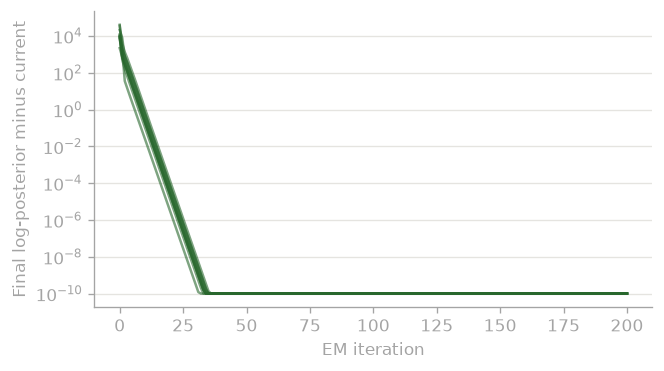

In [16]:
best = em_table["log-posterior"].max()
fig, ax = plt.subplots(figsize=(6, 3.2))
for history in histories:
    gap = np.maximum(best - history, 1e-10)
    ax.semilogy(np.arange(len(history)), gap, color=GREEN, alpha=0.6, linewidth=1.5)
ax.set_xlabel("EM iteration")
ax.set_ylabel("Final log-posterior minus current")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
fig.savefig("figures/layer2_em_convergence.pdf")
plt.show()

We mostly see straight lines. These mean the error shrinks by the same factor at every step, which is how EM usually converges.

Every run follows a straight line: the error is divided by about the same factor at each iteration (affine fct), until the gap reaches rounding level (gaps below $10^{-10}$ are drawn at $10^{-10}$). This is how EM usually converges so it is reassuring.

We know that starting EM with θ_E = θ_B is a bad start: both types then look identical, every session gets the same probability p0 of being Engaged whatever its skips, and EM has no reason to separate them. Our random starts from the prior never have θ_E = θ_B exactly, and all 10 reach the same mode

Lastly, we do importance sampling on yambda in the same way we did for the sample distributions earlier.

In [17]:
log_post = partial(st.log_posterior, skips=train_skips, mask=train_mask, prior=PRIOR)
fit = po.importance_sampling_at_mode(log_post, po.to_vector(mode, st.NAMES), N_DRAWS, rng, DF)
diagnostics = po.proposal_diagnostics(fit)
diagnostics.round(6)

draws outside the support (weight 0)        0.000000
draws                                   20000.000000
ESS                                     17268.686963
ESS share                                   0.863434
largest weight                              0.000070
dtype: float64

Here we see that no draw breaks the constraint, the largest weight is tiny, and the ESS is again about 86%, the Student-t(4)-on-Normal value. So the posterior is close to Normal on the log-odds scale, and the proposal, and thus the Hessian, fits the posterior on the real data too !

## 6. Posterior summaries

Now, we want to get the posterior means, standard deviations and 95% intervals of the self-normalized estimates. 

In [18]:
summary = po.posterior_table(fit, st.NAMES)
browsing_share = 1 - po.to_params(fit["draws"], st.NAMES)["p0"] # 1 - p_0 
summary.loc["share of Browsing sessions"] = pd.Series(po.weighted_summary(browsing_share, fit["weights"])) # has its own interval cus computed for each draw
summary.round(5)

,mean,sd,low,median,high
theta_e,0.10918,0.00226,0.10480,0.10918,0.11364
theta_b,0.76464,0.00315,0.75844,0.76465,0.77081
p0,0.53560,0.00808,0.51965,0.53554,0.55156
share of Browsing sessions,0.46440,0.00808,0.44844,0.46446,0.48035


So we have about 54% of angaged sessions, with a skip rate of about 0.11, and about 46% browsing sessions, with a skip rate of about 0.76.
Besideds, we also se that the standard deviations are narrow so we can have trust in our estimate.

### 6.1 Monte Carlo error
Can we trust the decimals of these means? Since they come from a single set of 20,000 draws, another seed could give different values. The Monte Carlo standard error of an estimator is its standard deviation over repeated runs. To measure it, we repeat the importance sampling on Yambda with 10 seeds and take the standard deviation of the posterior mean across seeds, (which should be much smaller than the posterior standard deviation).

In [19]:
seed_means = po.means_over_seeds(log_post, po.to_vector(mode, st.NAMES), N_DRAWS,
                                 range(1, 11), st.NAMES, DF)
monte_carlo = pd.DataFrame({"posterior sd": summary.loc[st.NAMES, "sd"],
                            "Monte Carlo error (sd over 10 seeds)": seed_means.std(ddof=1)})
monte_carlo

,posterior sd,Monte Carlo error (sd over 10 seeds)
theta_e,0.002264,0.000018
theta_b,0.003150,0.000032
p0,0.008080,0.000064


Here we see that the Monte Carlo error is about 100 times smaller than the posterior standard deviation for every parameter (about 0.00002 for θ_E, 0.00003 for θ_B, 0.00006 for p0). This makes sense since the weights are well balanced (high ESS). So 20,000 draws are enough: the uncertainty comes from the data, not from the sampling.

It is important to keep in mind that these intervals assume the model is right: it is the best two-type summary of the data. However, it does not take into account the fact that tracks are not independant from one another, and that many users have one session in each context, so sessions are not fully independent too, which makes real uncertainty larger than shown here.

### 6.2 Correlations between parameters
Now we want to know whether our three parameters move together. We compute their correlations from the weighted draws (we expect positive correlations, as we had seen on our second simulated data).

In [20]:
correlation = po.weighted_correlation(fit, st.NAMES)
correlation.round(3)

,theta_e,theta_b,p0
theta_e,1.000,0.435,0.226
theta_b,0.435,1.000,0.219
p0,0.226,0.219,1.000


We observe that θ_E and θ_B are positively correlated (about 0.4), and both are positively correlated with p0 (about 0.2). This comes from the fact that, as for our second simulated dataset, if the posterior calls more sessions Engaged, the extra ones are borderline sessions with a middle skip rate, so both skip rates go up. These correlations are weaker than on the simulated data set because the real types are further apart.

### 6.3 Marginal posteriors
Now we want to draw the posterior of each of our parameters. We plot the marginal posteriors as weighted histograms of the importance sampling draws

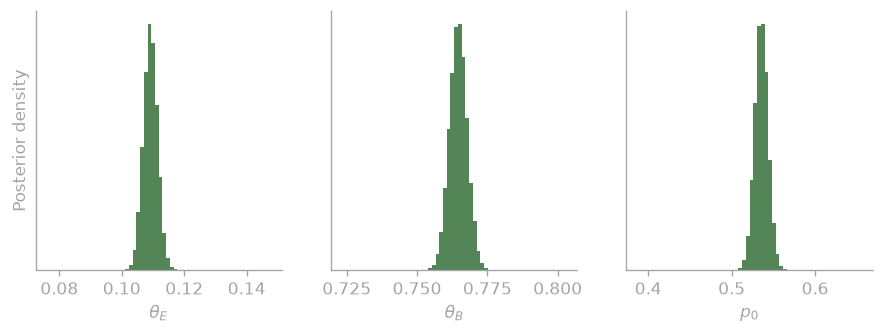

In [21]:
draw_params = po.to_params(fit["draws"], st.NAMES)
labels = {"theta_e": r"$\theta_E$", "theta_b": r"$\theta_B$", "p0": r"$p_0$"}
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8))
for ax, name in zip(axes, st.NAMES):
    ax.hist(draw_params[name], bins=60, weights=fit["weights"], density=True,
            histtype="stepfilled", color=GREEN, alpha=0.8)
    ax.set_xlabel(labels[name])
    ax.set_yticks([])
axes[0].set_ylabel("Posterior density")
fig.savefig("figures/layer2_posterior.pdf")
plt.show()

The three marginal posteriors are narrow and look like Normal curves, which makes sense since we have large ESS

### 6.4 Which sessions are Browsing?
Let's measure how clearly each session belongs to one type. 

First, for the rest of the notebook, we resample 1000 draws with probabilities equal to the weights, which gives equally weighted draws from the posterior. Then, for each session, we compute $P(z_i = B \mid y_i)$ by Bayes' rule, averaged over the 1000 draws (we expect most sessions to be close to 0 or 1).

964 different draws out of 1000
Sessions with P(Browsing) above 0.9: 0.441
Sessions with P(Browsing) below 0.1: 0.508
Sessions in between: 0.051


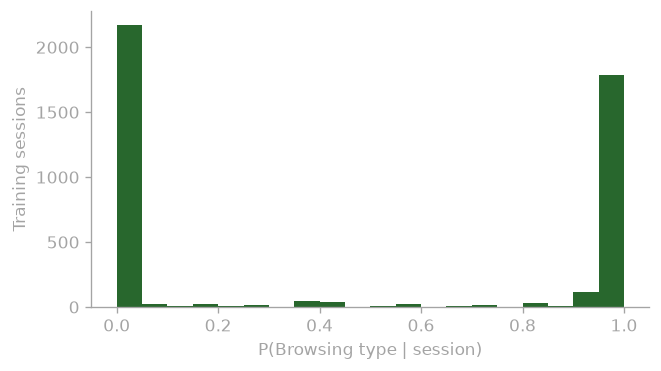

In [22]:
posterior_draws = po.resample(fit["draws"], fit["weights"], N_POSTERIOR, rng)
draws_params = [po.to_params(phi, st.NAMES) for phi in posterior_draws]
print(f"{len(np.unique(posterior_draws, axis=0))} different draws out of {N_POSTERIOR}")

p_browsing = sum(1 - st.type_probabilities(p, train_skips, train_mask)
                 for p in draws_params) / N_POSTERIOR
print(f"Sessions with P(Browsing) above 0.9: {(p_browsing > 0.9).mean():.3f}")
print(f"Sessions with P(Browsing) below 0.1: {(p_browsing < 0.1).mean():.3f}")
print(f"Sessions in between: {((p_browsing >= 0.1) & (p_browsing <= 0.9)).mean():.3f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(p_browsing, bins=20, range=(0, 1), color=GREEN)
ax.set_xlabel("P(Browsing type | session)")
ax.set_ylabel("Training sessions")
fig.savefig("figures/layer2_type_probabilities.pdf")
plt.show()

Here we see that most sessions are clearly one type: about 95% have a probability below 0.1 or above 0.9, and only about 5% are in between. This makes sense since, after 10 to 20 tracks, the number of skips almost always tells which group a session belongs to. Besides, almost all resampled draws are different points, so resampling did not lose much variety. We can therefore conclude that the two types are well separated on Yambda.

## 7. Posterior predictive checks
We have seen our model could well identify the real sessions. But is it able to reproduce them? 

To answer this we simulate sessions with the training lengths and compute six statistics for each of the 1000 posterior draws. The first three are those of Layer 1, and the last three are new:

- the gap after shuffling: the gap after a skip once the tracks are shuffled inside each session (20 shuffles): it keeps the differences between sessions but destroys the order,
- the within-session gap: gap after a skip minus gap after shuffling: the part that comes from the order inside a session,
- the number of skip/play changes per session

Given its type, a session's tracks are independent, so Layer 2 should give a within-session gap close to 0 . Besides, at the EM mode, each of the 14.6 neighbouring pairs of a session changes with probability $2\theta(1-\theta)$, so the expected number of changes is about $14.6 \times [0.536 \times 2 \times 0.109 \times 0.891 + 0.464 \times 2 \times 0.765 \times 0.235] \approx 3.9$ 

The real-data values use a fixed seed for the shuffles, so all layers report the same numbers.

In [23]:
observed = real_data_checks(train_skips, train_mask)
simulated = po.predictive_checks(st.simulate, draws_params, train_lengths, rng, all_checks)
check_table = po.predictive_table(simulated, observed)
check_table.round(4)

,real data,simulated mean,simulated 2.5%,simulated 97.5%,share at least as large
spread of skip rates,0.3584,0.3409,0.3368,0.3447,0.0
gap after a skip,0.6134,0.4406,0.4287,0.4524,0.0
longest run of skips,4.7731,3.6023,3.4640,3.7408,0.0
gap after shuffling,0.5121,0.4407,0.4297,0.4517,0.0
within-session gap,0.1013,-0.0001,-0.0047,0.0044,0.0
skip/play changes,2.7415,3.9486,3.8528,4.0445,1.0


As expected, the within-session gap is about 0 (and 0.10 for the real data), and the model predicts about 3.9 skip/play changes per session (and 2.74 for the real data), which matches the value found by hand. This makes sense since, given its type, a session's tracks are independent, so Layer 2 would not produce runs of skips. For every statistic, none of the 1000 simulations reaches the real value (or, for the changes, all are above it), so every statistic rejects the model.

One measure is surprising: the gap after shuffling is about 0.44 and not 0.51 like in the real data. We expected Layer 2 to explain the differences between sessions, and while it explains most of them it is incomplete and the spread of skip rates between sessions is also slightly too small.

### 7.1 Layers 1 and 2 side by side
How better is Layer 2 than Layer 1? We read Layer 1's table from `results/layer1.json`, computed with the same statistics, the same number of simulations and the same real-data values. We will now check wether layer 2 is closer to the real data for the statistics that come from differences between sessions.

In [24]:
if "predictive_checks" not in layer1:
    raise KeyError("results/layer1.json has no predictive_checks: rerun layer1_baseline.ipynb first")
layer1_checks = pd.DataFrame(layer1["predictive_checks"]).T
assert np.allclose(layer1_checks["real data"], check_table["real data"])

pd.DataFrame({
    "real data": check_table["real data"],
    "Layer 1 mean": layer1_checks["simulated mean"],
    "Layer 2 mean": check_table["simulated mean"],
    "Layer 1 share ≥ real": layer1_checks["share at least as large"],
    "Layer 2 share ≥ real": check_table["share at least as large"],
}).round(4)

,real data,Layer 1 mean,Layer 2 mean,Layer 1 share ≥ real,Layer 2 share ≥ real
spread of skip rates,0.3584,0.1294,0.3409,0.0,0.0
gap after a skip,0.6134,-0.0001,0.4406,0.0,0.0
longest run of skips,4.7731,2.7329,3.6023,0.0,0.0
gap after shuffling,0.5121,-0.0000,0.4407,0.0,0.0
within-session gap,0.1013,-0.0000,-0.0001,0.0,0.0
skip/play changes,2.7415,7.0859,3.9486,1.0,1.0


Here we see that Layer 2 is much closer than Layer 1 on every statistic that differences between sessions affect, which makes sense since this is exactly what the two types add. However, neither layer produces any within-session gap, which leaves the 0.10 for Layer 3 to reproduce.

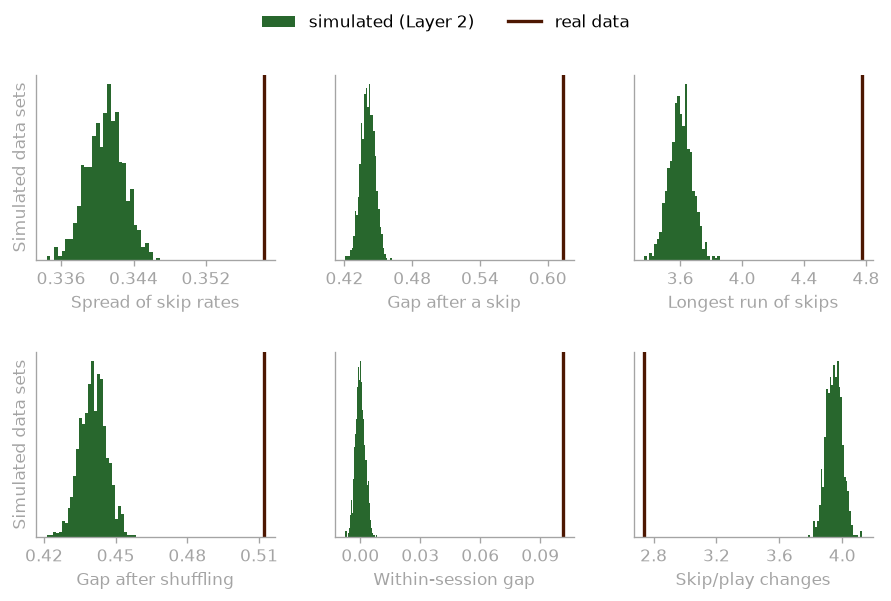

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for ax, name in zip(axes.ravel(), simulated.columns):
    ax.hist(simulated[name], bins=30, color=GREEN, label="simulated (Layer 2)")
    ax.axvline(observed[name], color=BROWN, linewidth=2, label="real data")
    ax.set_xlabel(name.capitalize())
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.set_yticks([])
axes[0, 0].set_ylabel("Simulated data sets")
axes[1, 0].set_ylabel("Simulated data sets")
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, frameon=False, loc="upper center", ncol=2)
fig.subplots_adjust(hspace=0.5, wspace=0.25)
fig.savefig("figures/layer2_predictive_checks.pdf")
plt.show()

In every panel the real value (brown) is still outside the simulated range (green): Layer 2 is better than Layer 1, but every statistic rejects it

### 7.2 Skip rate per session
Why is the gap after shuffling too small? Layer 2 says that sessions come in two groups, so we compare the distribution of the skip rate per session in the real training data with the one simulated from 20 posterior draws. If Layer 2 was right, the two distributions should match.

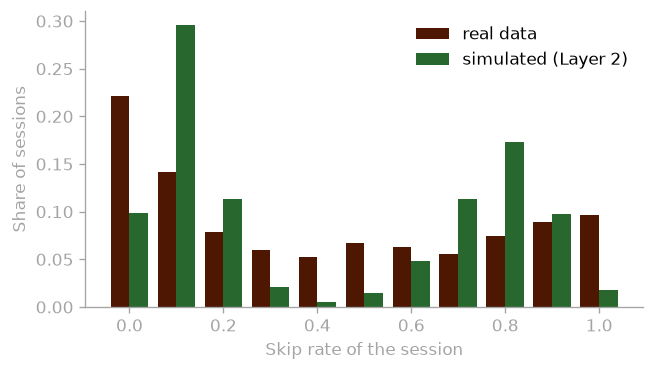

,real data,simulated (Layer 2)
no skip,0.221,0.099
at most 10% skips,0.337,0.316
30% to 70% skips,0.267,0.161
at least 90% skips,0.160,0.071
only skips,0.076,0.013


In [26]:
def session_rates(skips, mask):
    '''Return the skip rate of each session'''
    return (skips * mask).sum(axis=1) / mask.sum(axis=1)

real_rates = session_rates(train_skips, train_mask)
simulated_rates = np.concatenate([session_rates(*st.simulate(p, train_lengths, rng)[:2])
                                  for p in draws_params[:20]])

# bins centred on 0, 0.1, ..., 1, so sessions with 0% or 100% skips have their own bin
edges = np.linspace(-0.05, 1.05, 12)
real_share = np.histogram(real_rates, bins=edges)[0] / len(real_rates)
simulated_share = np.histogram(simulated_rates, bins=edges)[0] / len(simulated_rates)
centres = np.linspace(0, 1, 11)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(centres - 0.02, real_share, width=0.04, color=BROWN, label="real data")
ax.bar(centres + 0.02, simulated_share, width=0.04, color=GREEN, label="simulated (Layer 2)")
ax.set_xlabel("Skip rate of the session")
ax.set_ylabel("Share of sessions")
ax.legend(frameon=False)
fig.savefig("figures/layer2_skip_rate_per_session.pdf")
plt.show()

rate_groups = {
    "no skip": lambda r: r == 0,
    "at most 10% skips": lambda r: r <= 0.1,
    "30% to 70% skips": lambda r: (r >= 0.3) & (r <= 0.7),
    "at least 90% skips": lambda r: r >= 0.9,
    "only skips": lambda r: r == 1,
}
rate_table = pd.DataFrame({
    "real data": {name: rule(real_rates).mean() for name, rule in rate_groups.items()},
    "simulated (Layer 2)": {name: rule(simulated_rates).mean() for name, rule in rate_groups.items()},
})
rate_table.round(3)

Here we see that the real sessions are more varied than two types can make them. The real data have more sessions with no skip (22% against 10%), more sessions with only skips and more sessions in the middle (30% to 70% skips), while Layer 2 puts too many sessions near its two skip rates. This makes sense since, with θ_E ≈ 0.11 and about 15 tracks, an Engaged session has no skip with probability $0.89^{15.6} \approx 0.17$, so only about $0.54 \times 0.17 \approx 9\%$ of sessions have no skip, as simulated.

This is why the gap after shuffling is too small: real sessions differ from one another more than two fixed skip rates allow. Some of the difference may come from switching inside a session (Layer 3), which mixes engaged and browsing tracks, and the extremes (0% and 100%) may point to differences between listeners that two types cannot capture. We can therefore conclude that two fixed types are not enough to describe the real sessions.

## 8. Sensitivity to the prior
Now we will check wether our results depend on the prior. To do so, we repeat the fit (EM, then importance sampling) with Beta(1, 1) and Beta(5, 5) for all three parameters. For each prior, EM uses that prior raised by 1 (`log_odds_prior`), so the proposal is always centred at the right log-odds mode.

In [27]:
priors = {"Beta(1, 1)": (1, 1), "Beta(2, 2), main": (2, 2), "Beta(5, 5)": (5, 5)}
sensitivity = []
for label, (alpha, beta) in priors.items():
    prior = {name: (alpha, beta) for name in st.NAMES}
    prior_mode, _ = st.em(st.random_start(rng), train_skips, train_mask,
                          prior=po.log_odds_prior(prior))
    prior_log_post = partial(st.log_posterior, skips=train_skips, mask=train_mask, prior=prior)
    prior_fit = po.importance_sampling_at_mode(prior_log_post, po.to_vector(prior_mode, st.NAMES),
                                               N_DRAWS, rng, DF)
    table = po.posterior_table(prior_fit, st.NAMES)[["mean", "low", "high"]]
    table.insert(0, "prior", label)
    table["ESS share"] = prior_fit["ess_share"]
    sensitivity.append(table)
sensitivity = pd.concat(sensitivity)
sensitivity.round(5)

,prior,mean,low,high,ESS share
theta_e,"Beta(1, 1)",0.10911,0.10469,0.11365,0.86539
theta_b,"Beta(1, 1)",0.76461,0.75840,0.77078,0.86539
p0,"Beta(1, 1)",0.53552,0.51952,0.55133,0.86539
theta_e,"Beta(2, 2), main",0.10916,0.10481,0.11364,0.86655
theta_b,"Beta(2, 2), main",0.76460,0.75844,0.77074,0.86655
p0,"Beta(2, 2), main",0.53545,0.51958,0.55153,0.86655
theta_e,"Beta(5, 5)",0.10928,0.10482,0.11374,0.86230
theta_b,"Beta(5, 5)",0.76462,0.75844,0.77070,0.86230
p0,"Beta(5, 5)",0.53557,0.51954,0.55153,0.86230


Here we see that the three priors give the same posterior means and intervals to the 3rd decimal, and the ESS stays at about 86%. This makes sense since about 4300 sessions carry much more information than a prior worth a few observations. We can therefore conclude that our prior has little to no effect.

## 9. Additional analysis: predicting new listeners
Lastly, we want to know how well the model predicts the tracks of listeners it has never seen. This is not a check of the model: the checks are the validation on simulated data (section 3) and the posterior predictive checks (section 7). It is simply an extra question we wanted to explore with our model.

Each test track gets its posterior predictive probability of a skip given the earlier tracks of its session, and we average the logs of the probabilities given to what really happened.

The thing is that, unlike Layer 1, Layer 2 learns from the earlier tracks of the session: before track $t$, Bayes' rule updates the type probability with the $n_{<t}$ tracks and $s_{<t}$ skips seen so far (cumulative sums, no loop over tracks):

$$P(\text{skip at } t \mid y_{<t}) = P(E \mid y_{<t})\,\theta_E + P(B \mid y_{<t})\,\theta_B$$

At the first track this is $p_0 \theta_E + (1-p_0)\theta_B$. We average this probability over the 1000 posterior draws, and also compute it at the posterior mean as a check.

In [28]:
predictive = sum(st.skip_probabilities(p, test_skips, test_mask)
                 for p in draws_params) / N_POSTERIOR
score = average_log_score(predictive, test_skips, test_mask)

posterior_mean = {name: summary.loc[name, "mean"] for name in st.NAMES}
score_at_mean = average_log_score(st.skip_probabilities(posterior_mean, test_skips, test_mask),
                                  test_skips, test_mask)

print(f"Layer 2, averaged over the posterior: {score:.4f}")
print(f"Layer 2, at the posterior mean:       {score_at_mean:.4f}")
print(f"Layer 1, one skip rate:               {layer1['score_one_rate']:.4f}")
print(f"Fair coin:                            {np.log(0.5):.4f}")

Layer 2, averaged over the posterior: -0.4788
Layer 2, at the posterior mean:       -0.4789
Layer 1, one skip rate:               -0.6782
Fair coin:                            -0.6931


Here we see that Layer 2 is much better than Layer 1 on new users: −0.479 against −0.678 (fair coin −0.693). This happends because, after a few tracks, the model knows the type of the session and so predicts the next tracks much better. Besides, averaging over the posterior or using the posterior mean gives the same score, because the posterior is very narrow. 

This indicares that knowing the type of a session helps a lot in predicting wether its next tracks will be skipped. 

## 10. Save the results
Finally, we save every number in `results/layer2.json`, which Layer 3 reads to compare the three layers. The predictive-check table has the same six rows and the same columns as in `results/layer1.json`, and `em_mode` is the EM mode on the log-odds scale (the Beta(3, 3) run of section 3), written as probabilities.

In [29]:
def table_to_dict(table):
    '''Turn a DataFrame into a dict that json can write'''
    return json.loads(table.to_json(orient="index"))

results = {
    "em_mode": {name: float(value) for name, value in mode.items()},
    "posterior": table_to_dict(summary),
    "correlation": table_to_dict(correlation),
    "monte_carlo_error": {"seeds": 10, **table_to_dict(monte_carlo)},
    "importance_sampling": {"draws": N_DRAWS, "df": DF,
                            **table_to_dict(diagnostics.to_frame("value"))},
    "proposal_comparison": json.loads(comparison.to_json(orient="records")),
    "simulated_easy": {"true": TRUE,
                       "posterior": table_to_dict(po.posterior_table(sim_fit, st.NAMES, TRUE))},
    "simulated_hard": {"true": HARD,
                       "posterior": table_to_dict(po.posterior_table(hard_fit, st.NAMES, HARD))},
    "share_sessions_browsing_above_0.9": float((p_browsing > 0.9).mean()),
    "observed_checks": {name: float(value) for name, value in observed.items()},
    "predictive_checks": table_to_dict(check_table),
    "session_rate_groups": table_to_dict(rate_table),
    "score_posterior_predictive": float(score),
    "score_posterior_mean": float(score_at_mean),
    "prior_sensitivity": json.loads(sensitivity.reset_index(names="parameter")
                                    .to_json(orient="records")),
}
with open("results/layer2.json", "w") as file:
    json.dump(results, file, indent=2)
print(list(results))

['em_mode', 'posterior', 'correlation', 'monte_carlo_error', 'importance_sampling', 'proposal_comparison', 'simulated_easy', 'simulated_hard', 'share_sessions_browsing_above_0.9', 'observed_checks', 'predictive_checks', 'session_rate_groups', 'score_posterior_predictive', 'score_posterior_mean', 'prior_sensitivity']
